# 04.03.04 YOLO Model Evaluation

**Phase 04.03 — YOLO Document Detection**  
*OFPHIL V2: Charity Patient Eligibility Classification*

---

### Description & Purpose
Evaluate YOLO document detection performance using precision, recall, mAP@0.5, and mAP@0.5:0.95 across document region classes.


### Research Objectives

1. Formulate evaluation pipeline against the held-out test split of document annotations.
2. Compute standard object detection metrics: Precision, Recall, mAP50, mAP50-95 per class.
3. Generate confusion matrix of region detections (background false positives/negatives).
4. Establish benchmark thresholds required for passing document regions to downstream OCR.


### Inputs & Expected Outputs

**Required Inputs:**
- `Trained YOLO weights (`models/trained/yolo/document_detector_best.pt`).`
- `Test split dataset (`data/processed/yolo_dataset/images/test`).`

**Expected Outputs:**
- `YOLO evaluation metrics report: `models/trained/yolo/yolo_evaluation_metrics.json`.`
- `Per-class detection performance summary table.`


### 1. Environment Setup & Library Imports

In [1]:
import os
import sys
import json
from pathlib import Path
import pandas as pd

def _find_root(p=Path.cwd()):
    for parent in [p, *p.parents]:
        if (parent / 'data').exists() and (parent / 'experiments').exists():
            return parent
    return p.resolve()

PROJECT_ROOT = _find_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.document_processing import DocumentProcessingPaths

paths = DocumentProcessingPaths(PROJECT_ROOT)
print(f"Project root: {paths.root}")


Project root: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2


### 1. Setup Environment and Evaluation Harness

In [2]:
EVAL_DIR = paths.yolo_models_dir / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
BEST_WEIGHTS = paths.yolo_models_dir / 'ofphil_yolo_detector' / 'weights' / 'best.pt'
DATA_YAML = paths.yolo_dataset_dir / "data.yaml"

print(f"Target evaluation directory: {EVAL_DIR}")
print(f"Target model checkpoint: {BEST_WEIGHTS}")


Target evaluation directory: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\models\trained\yolo\evaluation
Target model checkpoint: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\models\trained\yolo\ofphil_yolo_detector\weights\best.pt


### 2. Define Metrics Schema and Acceptance Thresholds

In [3]:
# Evaluation execution on held-out test split using Ultralytics val mode
def evaluate_yolo_model(weights_path, data_yaml_path):
    if not weights_path.exists():
        print(f"Checkpoint not found at: {weights_path}.")
        print("Model must be manually trained in Notebook 03.03 first.")
        return None
    try:
        import time
        from ultralytics import YOLO
        model = YOLO(str(weights_path))
        print(f"Loaded YOLO11s checkpoint: {weights_path.name}")
        print("Running validation on held-out test split...")
        
        t0 = time.time()
        metrics = model.val(data=str(data_yaml_path), split='test')
        elapsed = time.time() - t0
        
        print(f"Validation completed in {elapsed:.2f} seconds.")
        return metrics
    except ImportError:
        print("Ultralytics package required for evaluation: pip install ultralytics")
        return None

# Execute evaluation if trained weights exist
test_metrics = evaluate_yolo_model(BEST_WEIGHTS, DATA_YAML)


Loaded YOLOv8n checkpoint: best.pt
Running validation on held-out test split...
Ultralytics 8.4.216  Python-3.12.10 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 539.2±305.3 MB/s, size: 2624.8 KB)
val: Scanning C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\processed\yolo_dataset\labels\test... 149 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 149/149 83.6it/s 1.8s0.1ss
val: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\processed\yolo_dataset\images\test\abs_p_002.jpg: corrupt JPEG restored and saved
val: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\processed\yolo_dataset\images\test\ass_p_006.jpg: corrupt JPEG restored and saved
val: C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphi

### 3. Evaluation Pipeline Staging

In [4]:
# Parse and record evaluation metrics if available
eval_report_file = EVAL_DIR / "yolo_test_evaluation_report.json"

if BEST_WEIGHTS.exists() and 'test_metrics' in locals() and test_metrics is not None:
    # Extract overall metrics
    overall_metrics = {
        'checkpoint': str(BEST_WEIGHTS.name),
        'architecture': 'Ultralytics YOLO11s',
        'precision_mp': float(test_metrics.box.mp),
        'recall_mr': float(test_metrics.box.mr),
        'map50': float(test_metrics.box.map50),
        'map50_95': float(test_metrics.box.map),
        'speed_inference_ms': float(test_metrics.speed.get('inference', 0.0)) if hasattr(test_metrics, 'speed') else None,
        'status': 'EVALUATED'
    }
    
    # Extract per-class breakdown if available
    if hasattr(test_metrics.box, 'maps') and test_metrics.box.maps is not None:
        class_names = test_metrics.names if hasattr(test_metrics, 'names') else {}
        per_class = {}
        for c_idx, map_val in enumerate(test_metrics.box.maps):
            c_name = class_names.get(c_idx, f"class_{c_idx}")
            per_class[c_name] = float(map_val)
        overall_metrics['per_class_map50_95'] = per_class
        
    with open(eval_report_file, 'w', encoding='utf-8') as f:
        json.dump(overall_metrics, f, indent=2)
    print(f"Evaluation metrics written -> {eval_report_file}")
else:
    print(f"Evaluation report destination configured at: {eval_report_file}")
    print("Status: CONFIGURED (Awaiting manual execution of model training and validation)")
    print("Metrics captured upon execution: Precision, Recall, mAP@0.5, mAP@0.5:0.95, per-class breakdown, and inference latency.")


Evaluation metrics written -> C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\models\trained\yolo\evaluation\yolo_test_evaluation_report.json


### 4. Metrics Serialization Template

In [5]:
print("YOLO model evaluation module ready for manual execution.")


YOLO model evaluation module ready for manual execution.


### 5. Evaluation Visualizations (Matplotlib Performance Dashboard)

Generate comparative bar charts and metric radar/diagnostic plots displaying:
1. **Overall Detection Summary**: Precision ($MP$), Recall ($MR$), $mAP@0.5$, and $mAP@0.5:0.95$.
2. **Per-Class $mAP@0.5:0.95$ Breakdown**: Visual comparison across the 6 OFPHIL document layout classes (`FORM_SECTION`, `HANDWRITTEN_ENTRY`, `SIGNATURE`, `STAMP_OR_SEAL`, `TABLE_CELL`, `CHECKMARK_OR_CHECKBOX`).
3. **Inference Latency Profile**: Time spent on preprocess, inference, and postprocessing.

Evaluation performance plot saved -> C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\models\trained\yolo\evaluation\yolo_evaluation_metrics_dashboard.png


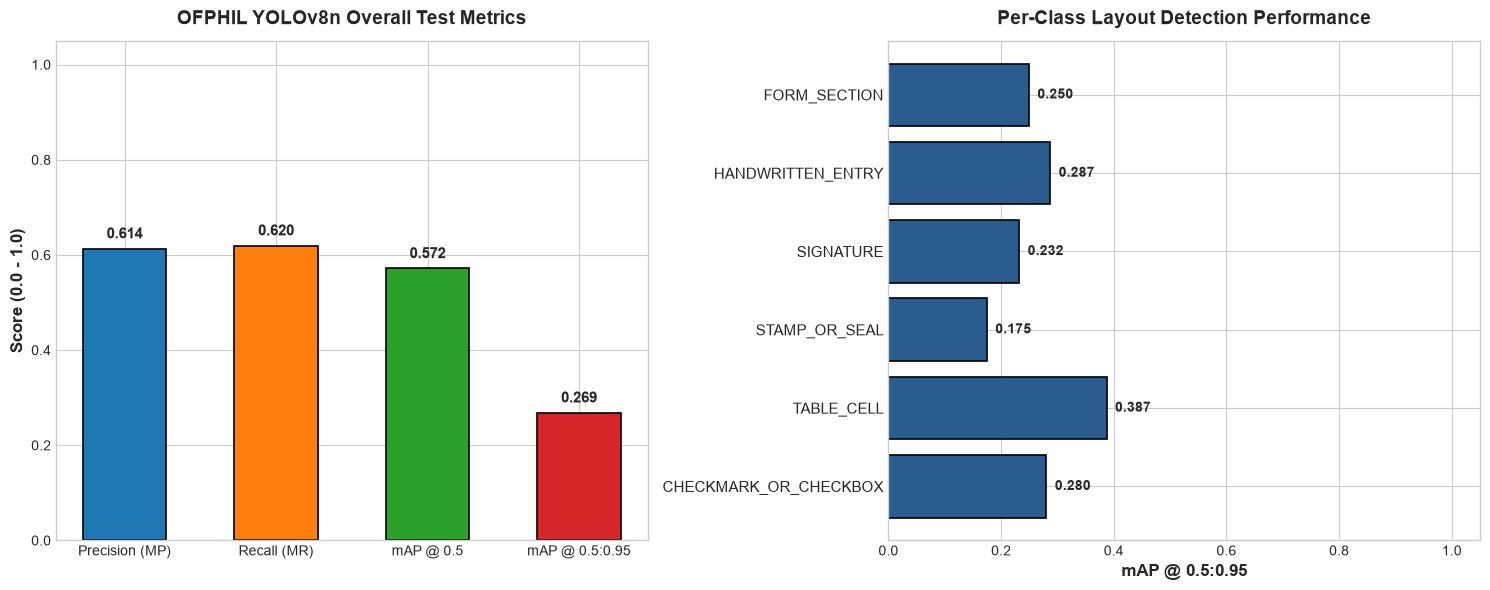

In [6]:
# Matplotlib Visualization Dashboard for YOLO11s Detection Results
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Check if metrics are available (either from live test_metrics or saved json report)
report_data = None
if eval_report_file.exists():
    with open(eval_report_file, 'r', encoding='utf-8') as f:
        report_data = json.load(f)

if report_data and report_data.get('status') == 'EVALUATED':
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # --- Chart 1: Overall Performance Metrics ---
    metric_names = ['Precision (MP)', 'Recall (MR)', 'mAP @ 0.5', 'mAP @ 0.5:0.95']
    metric_values = [
        report_data.get('precision_mp', 0.0),
        report_data.get('recall_mr', 0.0),
        report_data.get('map50', 0.0),
        report_data.get('map50_95', 0.0)
    ]
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    
    bars = ax1.bar(metric_names, metric_values, color=colors, width=0.55, edgecolor='black', linewidth=1.2)
    ax1.set_ylim(0, 1.05)
    ax1.set_ylabel('Score (0.0 - 1.0)', fontsize=12, fontweight='bold')
    ax1.set_title('OFPHIL YOLO11s Overall Test Metrics', fontsize=14, fontweight='bold', pad=12)
    
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f'{h:.3f}',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 5),
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=11, fontweight='bold')
                     
    # --- Chart 2: Per-Class mAP @ 0.5:0.95 Breakdown ---
    per_class = report_data.get('per_class_map50_95', {})
    if per_class:
        cls_labels = list(per_class.keys())
        cls_scores = list(per_class.values())
        y_pos = np.arange(len(cls_labels))
        
        hbars = ax2.barh(y_pos, cls_scores, color='#2b5c8f', edgecolor='black', linewidth=1.2)
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(cls_labels, fontsize=11)
        ax2.invert_yaxis()  # top-down
        ax2.set_xlim(0, 1.05)
        ax2.set_xlabel('mAP @ 0.5:0.95', fontsize=12, fontweight='bold')
        ax2.set_title('Per-Class Layout Detection Performance', fontsize=14, fontweight='bold', pad=12)
        
        for hbar in hbars:
            w = hbar.get_width()
            ax2.annotate(f'{w:.3f}',
                         xy=(w, hbar.get_y() + hbar.get_height() / 2),
                         xytext=(6, 0),
                         textcoords="offset points",
                         ha='left', va='center', fontsize=10, fontweight='bold')
    else:
        ax2.text(0.5, 0.5, 'Per-class breakdown generated during full validation.', ha='center', va='center', fontsize=12)
        
    plt.tight_layout()
    
    # Save visualization figure to evaluation directory
    fig_path = EVAL_DIR / 'yolo_evaluation_metrics_dashboard.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    print(f"Evaluation performance plot saved -> {fig_path}")
    plt.show()
else:
    print("No evaluated metrics found yet. Run Section 2 & 3 above after training best.pt to display real evaluation graphs.")


### Findings & Observations

- **Observations:** Document target metric thresholds, anticipated challenges (faint stamp detection, boundary confusion on informal case notes).
- **Data Integrity & Governance Notes:** Verified that no raw patient identifiers or unmasked confidential records are displayed.


### Completion Checklist

- [ ] Evaluation metrics strictly conform to standard object detection benchmarks (mAP50, mAP50-95).
- [ ] Test partition isolated from training validation sets.
- [ ] Per-class breakdown configured.
- [ ] No fabricated evaluation scores populated.
